# Demo 2: Open-Vocabulary Detection — Grounding DINO

**Model:** `IDEA-Research/grounding-dino-base`  
**Task:** Detect any object described by free-form text (no fixed class list)

---
**Flow:**
1. load an image from file
2. Load Grounding DINO model
3. Enter text query → detect objects and visualize results


In [ ]:

# ── Imports ──────────────────────────────────────────────────────────────────
import os
# GPU Advice Setting
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import warnings
warnings.filterwarnings('ignore')

## Step 1: Load Image

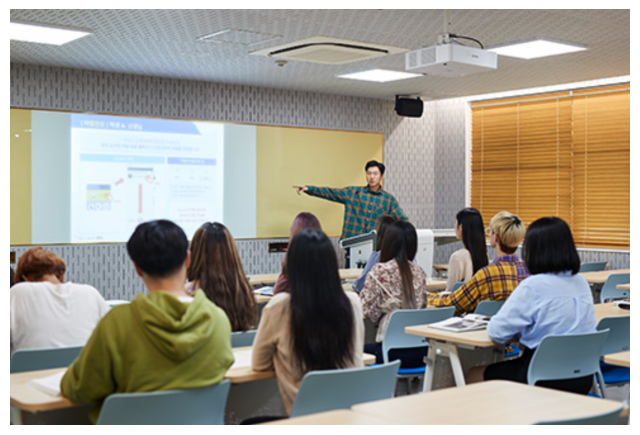

In [2]:
# ──  Load from file ──────────────────────────────────────────────────
IMAGE_PATH = "sample.png"
image = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(8, 6))
plt.imshow(image); plt.axis('off'); plt.show()

## Step 2: Load Grounding DINO Model

In [3]:
from models.dino_model import GroundingDINODetector
from utils.visualization import draw_boxes_on_image

dino = GroundingDINODetector()
dino.load()   # downloads model on first run (~340 MB)

[Grounding DINO] Loading IDEA-Research/grounding-dino-base on cuda ...
[Grounding DINO] Model loaded.


## Step 3: Detect Objects with a Text Query

Enter the objects you want to detect **separated by periods**.  
Example: `"a person. a face. a laptop."`

> Try changing only the query on the same image for an effective demo!


Detected 3 object(s)
  • a chair               score=0.358  box=[153, 694, 416, 781]
  • a chair               score=0.321  box=[523, 656, 735, 768]
  • a chair               score=0.314  box=[967, 598, 1127, 727]


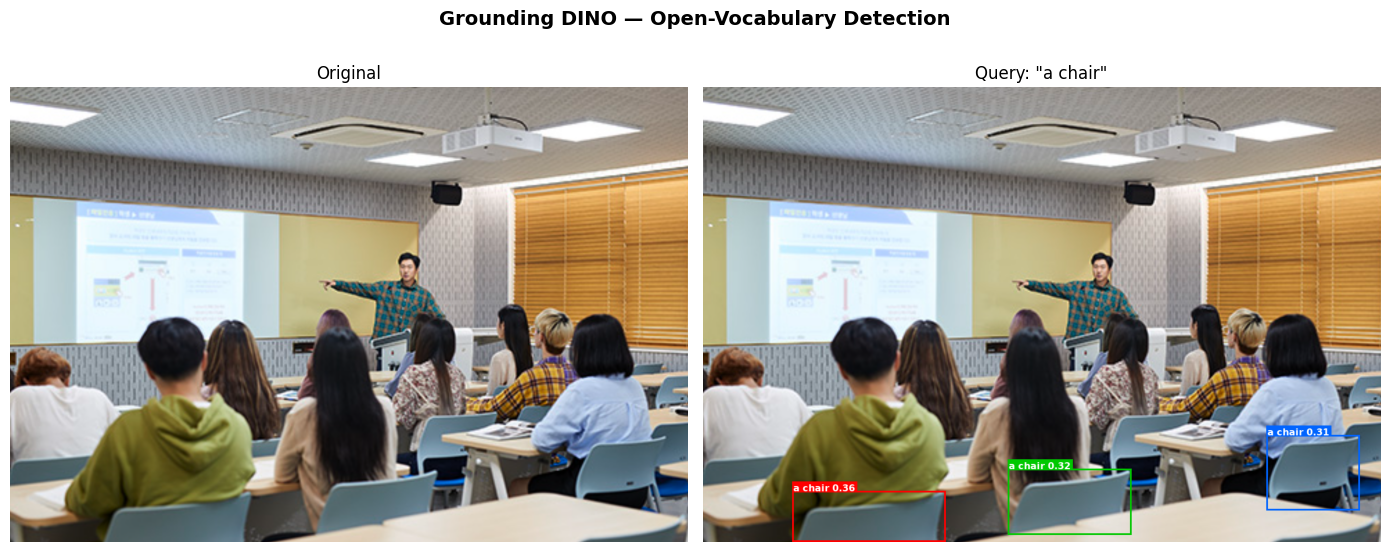

In [6]:
from utils.visualization import draw_boxes_on_image

# ─── Edit here ───────────────────────────────────────────────────────────────
TEXT_QUERY    = "a chair"
BOX_THRESHOLD = 0.3    # detections below this score are discarded (lower = more detections)
TEXT_THRESHOLD = 0.25
# ─────────────────────────────────────────────────────────────────────────────

boxes, scores, labels = dino.predict(
    image, TEXT_QUERY,
    box_threshold=BOX_THRESHOLD,
    text_threshold=TEXT_THRESHOLD,
)

print(f"Detected {len(boxes)} object(s)")
for label, score, box in zip(labels, scores, boxes):
    print(f"  • {label:<20s}  score={score:.3f}  box={[round(v) for v in box]}")

# Visualize
if boxes:
    result = draw_boxes_on_image(image, boxes, scores, labels)
else:
    result = image
    print("No objects detected — try lowering the threshold or changing the query.")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image);  axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(result); axes[1].set_title(f'Query: "{TEXT_QUERY}"'); axes[1].axis('off')
plt.suptitle("Grounding DINO — Open-Vocabulary Detection", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()